In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00


In [3]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
import os
import random
import shutil
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageEnhance
from sklearn.model_selection import train_test_split

In [5]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


In [6]:
!nvidia-smi

Sun Oct 11 22:33:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P0             45W /  400W |       6MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [20]:
SOURCE_DATASET = (
    "/content/drive/MyDrive/"
    "Deep Learning/"
    "IE7615 Deep Learning for AI"
)

OUTPUT_ROOT = (
    "/content/drive/MyDrive/"
    "Deep Learning/"
    "Milestone2_YOLO_Dataset"
)

print("Source exists:", os.path.exists(SOURCE_DATASET))
print("Output folder:", OUTPUT_ROOT)

Source exists: True
Output folder: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset


In [21]:
if os.path.exists(OUTPUT_ROOT):
    shutil.rmtree(OUTPUT_ROOT)

os.makedirs(OUTPUT_ROOT)

print("Fresh Milestone 2 folder created.")

Fresh Milestone 2 folder created.


In [22]:
valid_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

class_names = sorted([
    folder
    for folder in os.listdir(SOURCE_DATASET)
    if os.path.isdir(
        os.path.join(SOURCE_DATASET, folder)
    )
])

num_classes = len(class_names)

print("Number of classes:", num_classes)

for index, class_name in enumerate(class_names):
    print(index, class_name)

Number of classes: 73
0 images_OBJ001
1 images_OBJ002
2 images_OBJ003
3 images_OBJ004
4 images_OBJ005
5 images_OBJ006
6 images_OBJ007
7 images_OBJ008
8 images_OBJ009
9 images_OBJ010
10 images_OBJ011
11 images_OBJ012
12 images_OBJ013
13 images_OBJ014
14 images_OBJ015
15 images_OBJ016
16 images_OBJ017
17 images_OBJ018
18 images_OBJ019
19 images_OBJ020
20 images_OBJ021
21 images_OBJ022
22 images_OBJ023
23 images_OBJ024
24 images_OBJ025
25 images_OBJ026
26 images_OBJ027
27 images_OBJ028
28 images_OBJ029
29 images_OBJ030
30 images_OBJ031
31 images_OBJ032
32 images_OBJ033
33 images_OBJ034
34 images_OBJ035
35 images_OBJ036
36 images_OBJ037
37 images_OBJ038
38 images_OBJ039
39 images_OBJ040
40 images_OBJ041
41 images_OBJ042
42 images_OBJ043
43 images_OBJ044
44 images_OBJ045
45 images_OBJ046
46 images_OBJ047
47 images_OBJ048
48 images_OBJ049
49 images_OBJ050
50 images_OBJ051
51 images_OBJ052
52 images_OBJ053
53 images_OBJ054
54 images_OBJ055
55 images_OBJ056
56 images_OBJ057
57 images_OBJ058
58

In [23]:
class_to_id = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

class_to_id

{'images_OBJ001': 0,
 'images_OBJ002': 1,
 'images_OBJ003': 2,
 'images_OBJ004': 3,
 'images_OBJ005': 4,
 'images_OBJ006': 5,
 'images_OBJ007': 6,
 'images_OBJ008': 7,
 'images_OBJ009': 8,
 'images_OBJ010': 9,
 'images_OBJ011': 10,
 'images_OBJ012': 11,
 'images_OBJ013': 12,
 'images_OBJ014': 13,
 'images_OBJ015': 14,
 'images_OBJ016': 15,
 'images_OBJ017': 16,
 'images_OBJ018': 17,
 'images_OBJ019': 18,
 'images_OBJ020': 19,
 'images_OBJ021': 20,
 'images_OBJ022': 21,
 'images_OBJ023': 22,
 'images_OBJ024': 23,
 'images_OBJ025': 24,
 'images_OBJ026': 25,
 'images_OBJ027': 26,
 'images_OBJ028': 27,
 'images_OBJ029': 28,
 'images_OBJ030': 29,
 'images_OBJ031': 30,
 'images_OBJ032': 31,
 'images_OBJ033': 32,
 'images_OBJ034': 33,
 'images_OBJ035': 34,
 'images_OBJ036': 35,
 'images_OBJ037': 36,
 'images_OBJ038': 37,
 'images_OBJ039': 38,
 'images_OBJ040': 39,
 'images_OBJ041': 40,
 'images_OBJ042': 41,
 'images_OBJ043': 42,
 'images_OBJ044': 43,
 'images_OBJ045': 44,
 'images_OBJ046': 45

In [24]:
class_images = {}

for class_name in class_names:

    class_path = os.path.join(
        SOURCE_DATASET,
        class_name
    )

    images = [
        os.path.join(class_path, filename)
        for filename in os.listdir(class_path)
        if filename.lower().endswith(valid_extensions)
    ]

    class_images[class_name] = images

    print(
        f"{class_name}: {len(images)} images"
    )

images_OBJ001: 100 images
images_OBJ002: 100 images
images_OBJ003: 100 images
images_OBJ004: 100 images
images_OBJ005: 108 images
images_OBJ006: 100 images
images_OBJ007: 100 images
images_OBJ008: 100 images
images_OBJ009: 106 images
images_OBJ010: 100 images
images_OBJ011: 100 images
images_OBJ012: 100 images
images_OBJ013: 100 images
images_OBJ014: 100 images
images_OBJ015: 100 images
images_OBJ016: 100 images
images_OBJ017: 113 images
images_OBJ018: 100 images
images_OBJ019: 100 images
images_OBJ020: 100 images
images_OBJ021: 100 images
images_OBJ022: 100 images
images_OBJ023: 100 images
images_OBJ024: 100 images
images_OBJ025: 100 images
images_OBJ026: 100 images
images_OBJ027: 100 images
images_OBJ028: 101 images
images_OBJ029: 100 images
images_OBJ030: 100 images
images_OBJ031: 100 images
images_OBJ032: 100 images
images_OBJ033: 100 images
images_OBJ034: 100 images
images_OBJ035: 100 images
images_OBJ036: 100 images
images_OBJ037: 100 images
images_OBJ038: 100 images
images_OBJ03

In [25]:
NUM_2X2 = 200
NUM_3X3 = 200

TOTAL_IMAGES = NUM_2X2 + NUM_3X3

CANVAS_SIZE = 640

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("2x2 images:", NUM_2X2)
print("3x3 images:", NUM_3X3)
print("Total:", TOTAL_IMAGES)

2x2 images: 200
3x3 images: 200
Total: 400


In [26]:
generated_images_dir = os.path.join(
    OUTPUT_ROOT,
    "generated_images"
)

generated_labels_dir = os.path.join(
    OUTPUT_ROOT,
    "generated_labels"
)

os.makedirs(
    generated_images_dir,
    exist_ok=True
)

os.makedirs(
    generated_labels_dir,
    exist_ok=True
)

print("Images:", generated_images_dir)
print("Labels:", generated_labels_dir)

Images: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/generated_images
Labels: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/generated_labels


In [27]:
def augment_image(img):

    # Horizontal flip
    if random.random() < 0.5:
        img = img.transpose(
            Image.Transpose.FLIP_LEFT_RIGHT
        )

    # Brightness variation
    brightness = random.uniform(
        0.85,
        1.15
    )

    img = ImageEnhance.Brightness(
        img
    ).enhance(brightness)

    # Contrast variation
    contrast = random.uniform(
        0.85,
        1.15
    )

    img = ImageEnhance.Contrast(
        img
    ).enhance(contrast)

    return img

# Multi-object generation

In [28]:
def generate_multi_object_image(
    image_index,
    grid_size,
    min_objects,
    max_objects
):

    # Small white space between cells
    GAP = 4

    canvas = Image.new(
        "RGB",
        (CANVAS_SIZE, CANVAS_SIZE),
        (255, 255, 255)
    )

    cell_size = CANVAS_SIZE // grid_size

    grid_cells = []

    for row in range(grid_size):

        for col in range(grid_size):

            x = col * cell_size
            y = row * cell_size

            grid_cells.append(
                (x, y)
            )

    max_allowed = min(
        max_objects,
        len(grid_cells),
        len(class_names)
    )

    num_objects = random.randint(
        min_objects,
        max_allowed
    )

    # Different object IDs within one generated image
    selected_classes = random.sample(
        class_names,
        num_objects
    )

    # Random cells
    selected_cells = random.sample(
        grid_cells,
        num_objects
    )

    annotations = []

    for class_name, (cell_x, cell_y) in zip(
        selected_classes,
        selected_cells
    ):

        source_path = random.choice(
            class_images[class_name]
        )

        try:
            image = Image.open(
                source_path
            ).convert("RGB")

        except Exception as e:
            print("Could not load:", source_path)
            continue

        image = augment_image(
            image
        )

        target_size = (
            cell_size - 2 * GAP
        )

        # Fill almost the entire cell.
        # We resize instead of using thumbnail,
        # which removes the huge blank spaces.
        image = image.resize(
            (target_size, target_size),
            Image.Resampling.LANCZOS
        )

        paste_x = cell_x + GAP
        paste_y = cell_y + GAP

        canvas.paste(
            image,
            (paste_x, paste_y)
        )

        # Bounding box coordinates
        x_min = paste_x
        y_min = paste_y

        x_max = paste_x + target_size
        y_max = paste_y + target_size

        # Convert to YOLO format
        x_center = (
            (x_min + x_max) / 2
        ) / CANVAS_SIZE

        y_center = (
            (y_min + y_max) / 2
        ) / CANVAS_SIZE

        box_width = (
            x_max - x_min
        ) / CANVAS_SIZE

        box_height = (
            y_max - y_min
        ) / CANVAS_SIZE

        class_id = class_to_id[
            class_name
        ]

        annotations.append(
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

    layout = f"{grid_size}x{grid_size}"

    image_filename = (
        f"{layout}_multi_{image_index:04d}.jpg"
    )

    label_filename = (
        f"{layout}_multi_{image_index:04d}.txt"
    )

    # Save image
    canvas.save(
        os.path.join(
            generated_images_dir,
            image_filename
        ),
        quality=95
    )

    # Save corresponding YOLO annotation
    with open(
        os.path.join(
            generated_labels_dir,
            label_filename
        ),
        "w"
    ) as file:

        file.write(
            "\n".join(annotations)
        )

## Generate 2×2 images

In [29]:
for i in range(NUM_2X2):

    generate_multi_object_image(
        image_index=i,
        grid_size=2,
        min_objects=2,
        max_objects=4
    )

print(
    f"Generated {NUM_2X2} 2x2 images."
)

Generated 200 2x2 images.


## Generate 3×3 images

In [30]:
for i in range(NUM_3X3):

    generate_multi_object_image(
        image_index=i,
        grid_size=3,
        min_objects=4,
        max_objects=9
    )

print(
    f"Generated {NUM_3X3} 3x3 images."
)

Generated 200 3x3 images.


## Verify 400 images

In [31]:
generated_images = sorted([
    file
    for file in os.listdir(
        generated_images_dir
    )
    if file.lower().endswith(".jpg")
])

generated_labels = sorted([
    file
    for file in os.listdir(
        generated_labels_dir
    )
    if file.lower().endswith(".txt")
])

print(
    "Generated images:",
    len(generated_images)
)

print(
    "Generated labels:",
    len(generated_labels)
)

Generated images: 400
Generated labels: 400


In [32]:
count_2x2 = sum(
    file.startswith("2x2")
    for file in generated_images
)

count_3x3 = sum(
    file.startswith("3x3")
    for file in generated_images
)

print("2x2:", count_2x2)
print("3x3:", count_3x3)

2x2: 200
3x3: 200


In [33]:
sample_2x2 = random.choice([
    file
    for file in generated_images
    if file.startswith("2x2")
])

sample_3x3 = random.choice([
    file
    for file in generated_images
    if file.startswith("3x3")
])

print("2x2:", sample_2x2)
print("3x3:", sample_3x3)

2x2: 2x2_multi_0175.jpg
3x3: 3x3_multi_0060.jpg


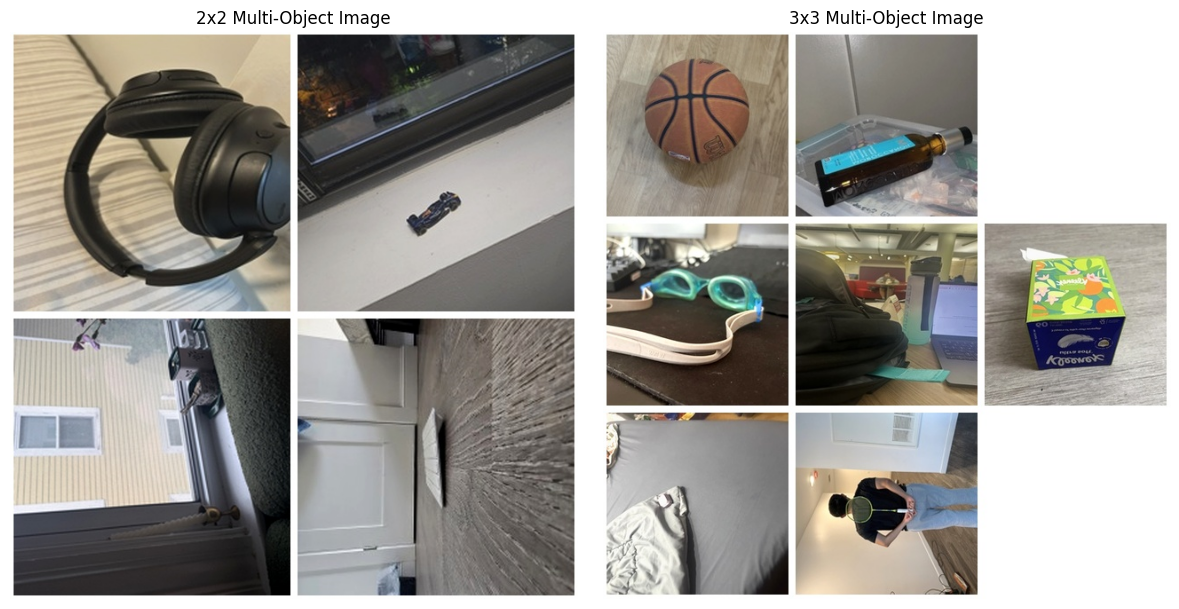

In [34]:
plt.figure(
    figsize=(12, 6)
)

# 2x2
plt.subplot(
    1,
    2,
    1
)

image = Image.open(
    os.path.join(
        generated_images_dir,
        sample_2x2
    )
)

plt.imshow(image)
plt.title("2x2 Multi-Object Image")
plt.axis("off")


# 3x3
plt.subplot(
    1,
    2,
    2
)

image = Image.open(
    os.path.join(
        generated_images_dir,
        sample_3x3
    )
)

plt.imshow(image)
plt.title("3x3 Multi-Object Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
import matplotlib.patches as patches

def show_annotations(image_filename):

    image_path = os.path.join(
        generated_images_dir,
        image_filename
    )

    label_path = os.path.join(
        generated_labels_dir,
        image_filename.replace(
            ".jpg",
            ".txt"
        )
    )

    image = Image.open(
        image_path
    )

    fig, ax = plt.subplots(
        figsize=(9, 9)
    )

    ax.imshow(image)

    with open(
        label_path,
        "r"
    ) as file:

        for line in file:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(
                values[0]
            )

            x_center = float(
                values[1]
            )

            y_center = float(
                values[2]
            )

            width = float(
                values[3]
            )

            height = float(
                values[4]
            )

            box_width = (
                width * CANVAS_SIZE
            )

            box_height = (
                height * CANVAS_SIZE
            )

            x = (
                x_center * CANVAS_SIZE
                - box_width / 2
            )

            y = (
                y_center * CANVAS_SIZE
                - box_height / 2
            )

            rectangle = patches.Rectangle(
                (x, y),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(
                rectangle
            )

            ax.text(
                x + 3,
                y + 12,
                class_names[class_id],
                fontsize=7,
                backgroundcolor="white"
            )

    plt.title(
        image_filename
    )

    plt.axis("off")
    plt.show()

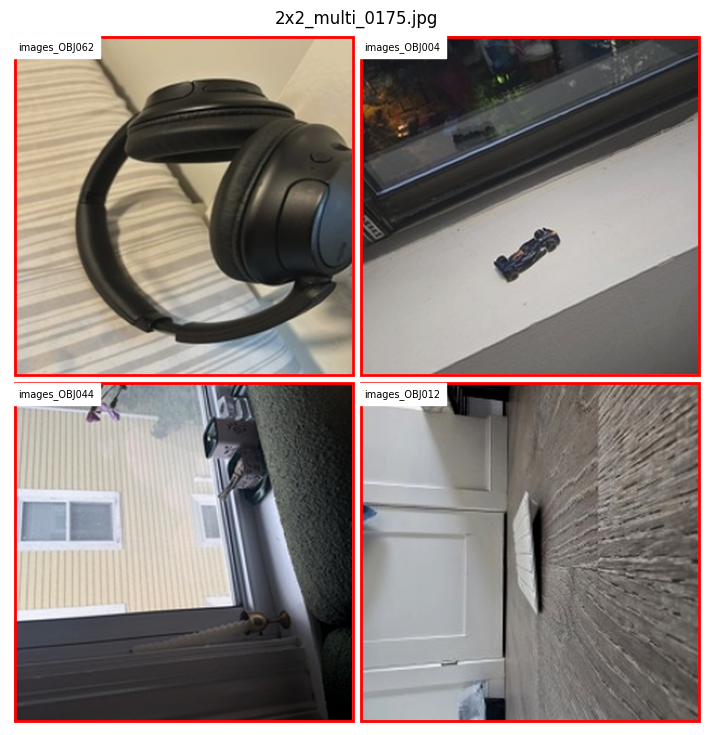

In [37]:
show_annotations(
    sample_2x2
)

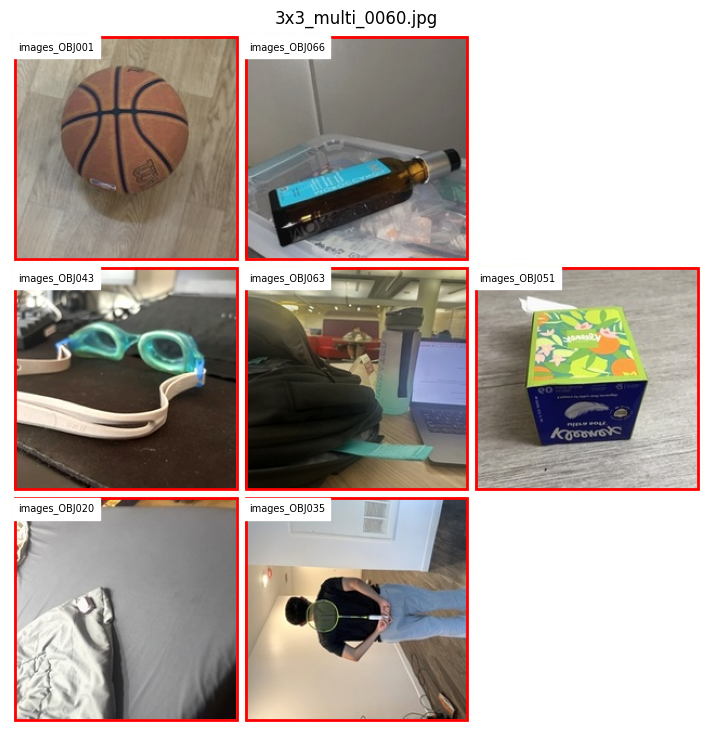

In [38]:
show_annotations(
    sample_3x3
)

In [39]:
files_2x2 = [
    f for f in generated_images
    if f.startswith("2x2")
]

files_3x3 = [
    f for f in generated_images
    if f.startswith("3x3")
]

print("2x2 images:", len(files_2x2))
print("3x3 images:", len(files_3x3))

2x2 images: 200
3x3 images: 200


In [40]:
train_2x2, temp_2x2 = train_test_split(
    files_2x2,
    test_size=0.30,
    random_state=SEED
)

val_2x2, test_2x2 = train_test_split(
    temp_2x2,
    test_size=0.50,
    random_state=SEED
)

train_3x3, temp_3x3 = train_test_split(
    files_3x3,
    test_size=0.30,
    random_state=SEED
)

val_3x3, test_3x3 = train_test_split(
    temp_3x3,
    test_size=0.50,
    random_state=SEED
)

train_files = train_2x2 + train_3x3
val_files = val_2x2 + val_3x3
test_files = test_2x2 + test_3x3

random.shuffle(train_files)
random.shuffle(val_files)
random.shuffle(test_files)

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))

Training: 280
Validation: 60
Testing: 60


In [41]:
for split in ["train", "val", "test"]:

    os.makedirs(
        os.path.join(
            OUTPUT_ROOT,
            "images",
            split
        ),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(
            OUTPUT_ROOT,
            "labels",
            split
        ),
        exist_ok=True
    )

print("YOLO folder structure created.")

YOLO folder structure created.


In [42]:
def copy_split(files, split):

    for image_file in files:

        label_file = image_file.replace(
            ".jpg",
            ".txt"
        )

        shutil.copy(
            os.path.join(
                generated_images_dir,
                image_file
            ),
            os.path.join(
                OUTPUT_ROOT,
                "images",
                split,
                image_file
            )
        )

        shutil.copy(
            os.path.join(
                generated_labels_dir,
                label_file
            ),
            os.path.join(
                OUTPUT_ROOT,
                "labels",
                split,
                label_file
            )
        )


copy_split(train_files, "train")
copy_split(val_files, "val")
copy_split(test_files, "test")

print("Dataset copied into YOLO folders.")

Dataset copied into YOLO folders.


In [43]:
for split in ["train", "val", "test"]:

    image_folder = os.path.join(
        OUTPUT_ROOT,
        "images",
        split
    )

    files = os.listdir(image_folder)

    count_2x2 = sum(
        f.startswith("2x2")
        for f in files
    )

    count_3x3 = sum(
        f.startswith("3x3")
        for f in files
    )

    print(
        f"{split}: "
        f"{len(files)} total | "
        f"{count_2x2} 2x2 | "
        f"{count_3x3} 3x3"
    )

train: 280 total | 140 2x2 | 140 3x3
val: 60 total | 30 2x2 | 30 3x3
test: 60 total | 30 2x2 | 30 3x3


In [44]:
yaml_data = {
    "path": OUTPUT_ROOT,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",

    "nc": num_classes,

    "names": {
        i: name
        for i, name in enumerate(class_names)
    }
}

yaml_path = os.path.join(
    OUTPUT_ROOT,
    "data.yaml"
)

with open(
    yaml_path,
    "w"
) as file:

    yaml.dump(
        yaml_data,
        file,
        sort_keys=False
    )

print("Created:", yaml_path)

Created: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/data.yaml


In [45]:
with open(
    yaml_path,
    "r"
) as file:

    print(file.read())

path: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset
train: images/train
val: images/val
test: images/test
nc: 73
names:
  0: images_OBJ001
  1: images_OBJ002
  2: images_OBJ003
  3: images_OBJ004
  4: images_OBJ005
  5: images_OBJ006
  6: images_OBJ007
  7: images_OBJ008
  8: images_OBJ009
  9: images_OBJ010
  10: images_OBJ011
  11: images_OBJ012
  12: images_OBJ013
  13: images_OBJ014
  14: images_OBJ015
  15: images_OBJ016
  16: images_OBJ017
  17: images_OBJ018
  18: images_OBJ019
  19: images_OBJ020
  20: images_OBJ021
  21: images_OBJ022
  22: images_OBJ023
  23: images_OBJ024
  24: images_OBJ025
  25: images_OBJ026
  26: images_OBJ027
  27: images_OBJ028
  28: images_OBJ029
  29: images_OBJ030
  30: images_OBJ031
  31: images_OBJ032
  32: images_OBJ033
  33: images_OBJ034
  34: images_OBJ035
  35: images_OBJ036
  36: images_OBJ037
  37: images_OBJ038
  38: images_OBJ039
  39: images_OBJ040
  40: images_OBJ041
  41: images_OBJ042
  42: images_OBJ043
  43: images_OB

In [46]:
model = YOLO(
    "yolov8s.pt"
)

print("YOLOv8s loaded successfully.")

YOLOv8s loaded successfully.


In [47]:
results = model.train(
    data=yaml_path,

    epochs=50,
    imgsz=640,
    batch=32,

    device=0,

    patience=10,

    workers=8,

    cache="ram",

    pretrained=True,

    project="/content/drive/MyDrive/Deep Learning/YOLO_Runs",

    name="Milestone2_YOLOv8s_Mixed"
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Milesto

In [48]:
from ultralytics import YOLO

best_model_path = (
    "/content/drive/MyDrive/Deep Learning/"
    "YOLO_Runs/Milestone2_YOLOv8s_Mixed/"
    "weights/best.pt"
)

best_model = YOLO(best_model_path)

print("Best YOLOv8 model loaded.")

Best YOLOv8 model loaded.


In [49]:
import os
import random

test_folder = (
    "/content/drive/MyDrive/Deep Learning/"
    "Milestone2_YOLO_Dataset/images/test"
)

test_images = os.listdir(test_folder)

test_2x2 = random.choice([
    f for f in test_images
    if f.startswith("2x2")
])

test_3x3 = random.choice([
    f for f in test_images
    if f.startswith("3x3")
])

print("2x2 image:", test_2x2)
print("3x3 image:", test_3x3)

2x2 image: 2x2_multi_0195.jpg
3x3 image: 3x3_multi_0068.jpg


In [56]:
prediction_2x2 = best_model.predict(
    source=os.path.join(
        test_folder,
        test_2x2
    ),
    conf=0.15,
    imgsz=640
)


image 1/1 /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/images/test/2x2_multi_0195.jpg: 640x640 1 images_OBJ015, 1 images_OBJ037, 1 images_OBJ063, 8.5ms
Speed: 1.1ms preprocess, 8.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


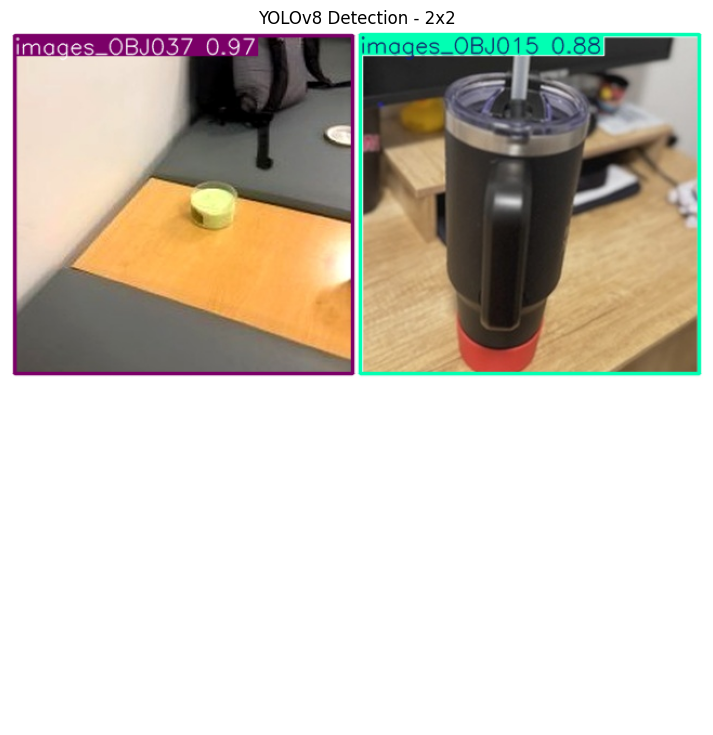

In [57]:
import matplotlib.pyplot as plt

result_2x2 = prediction_2x2[0]

annotated_2x2 = result_2x2.plot()

plt.figure(figsize=(9, 9))

plt.imshow(
    annotated_2x2[..., ::-1]
)

plt.title("YOLOv8 Detection - 2x2")

plt.axis("off")

plt.show()

In [54]:
prediction_3x3 = best_model.predict(
    source=os.path.join(
        test_folder,
        test_3x3
    ),
    conf=0.15,
    imgsz=640
)


image 1/1 /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/images/test/3x3_multi_0068.jpg: 640x640 1 images_OBJ004, 1 images_OBJ018, 1 images_OBJ024, 1 images_OBJ046, 1 images_OBJ048, 1 images_OBJ052, 1 images_OBJ059, 1 images_OBJ060, 9.7ms
Speed: 1.7ms preprocess, 9.7ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 640)


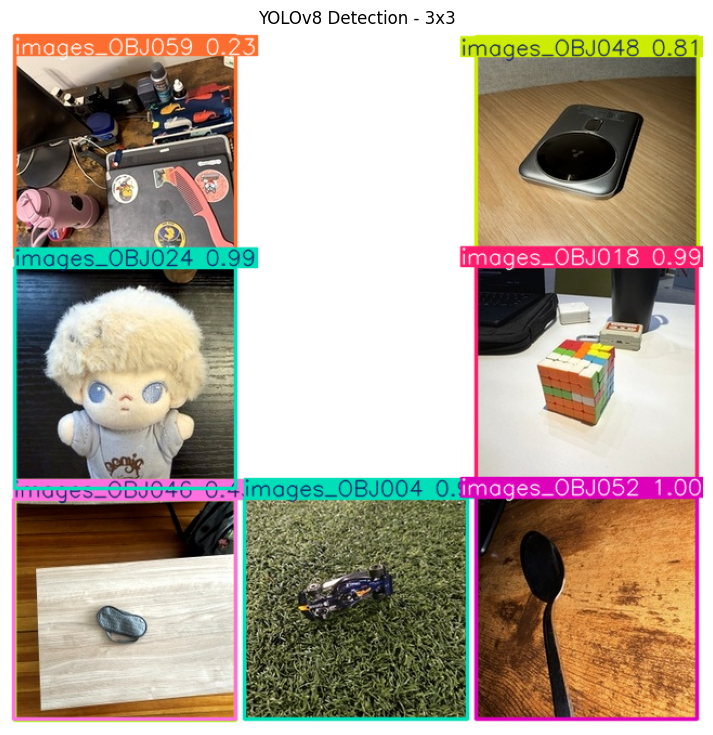

In [55]:
result_3x3 = prediction_3x3[0]

annotated_3x3 = result_3x3.plot()

plt.figure(figsize=(9, 9))

plt.imshow(
    annotated_3x3[..., ::-1]
)

plt.title("YOLOv8 Detection - 3x3")

plt.axis("off")

plt.show()

In [58]:
def print_detections(result):

    for i, box in enumerate(result.boxes):

        class_id = int(box.cls[0])

        confidence = float(box.conf[0])

        x1, y1, x2, y2 = (
            box.xyxy[0]
            .cpu()
            .numpy()
        )

        print(f"Object {i + 1}")

        print(
            f"ID: {result.names[class_id]}"
        )

        print(
            f"Confidence: {confidence:.3f}"
        )

        print(
            f"Location: "
            f"x1={x1:.1f}, "
            f"y1={y1:.1f}, "
            f"x2={x2:.1f}, "
            f"y2={y2:.1f}"
        )

        print("-" * 40)

In [59]:
print("2x2 DETECTIONS")
print_detections(result_2x2)

print("\n3x3 DETECTIONS")
print_detections(result_3x3)

2x2 DETECTIONS
Object 1
ID: images_OBJ037
Confidence: 0.968
Location: x1=4.7, y1=3.7, x2=316.2, y2=315.7
----------------------------------------
Object 2
ID: images_OBJ015
Confidence: 0.878
Location: x1=323.9, y1=2.3, x2=636.0, y2=315.8
----------------------------------------
Object 3
ID: images_OBJ063
Confidence: 0.372
Location: x1=324.1, y1=4.0, x2=636.2, y2=316.2
----------------------------------------

3x3 DETECTIONS
Object 1
ID: images_OBJ052
Confidence: 0.996
Location: x1=430.1, y1=429.8, x2=634.5, y2=634.4
----------------------------------------
Object 2
ID: images_OBJ024
Confidence: 0.991
Location: x1=4.4, y1=217.4, x2=208.8, y2=421.7
----------------------------------------
Object 3
ID: images_OBJ018
Confidence: 0.988
Location: x1=430.0, y1=217.0, x2=635.0, y2=421.9
----------------------------------------
Object 4
ID: images_OBJ004
Confidence: 0.988
Location: x1=216.2, y1=430.2, x2=422.5, y2=634.4
----------------------------------------
Object 5
ID: images_OBJ048
Confide

In [61]:
test_metrics = best_model.val(
    data=yaml_path,
    split="test"
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 116.1±33.5 MB/s, size: 119.5 KB)
val: Scanning /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 516.7it/s 0.1s
val: New cache created: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.8it/s 2.2s
                   all         60        288      0.843      0.753      0.831       0.83
         images_OBJ001          3          3      0.833      0.667      0.665      0.665
         images_OBJ002          7          7      0.958          1      0.995      0.995
         images_OBJ003          6          6      0.679      0.333      0.718

In [62]:
print(f"Precision: {test_metrics.box.mp:.4f}")
print(f"Recall: {test_metrics.box.mr:.4f}")
print(f"mAP@0.50: {test_metrics.box.map50:.4f}")
print(f"mAP@0.50:0.95: {test_metrics.box.map:.4f}")

Precision: 0.8434
Recall: 0.7530
mAP@0.50: 0.8306
mAP@0.50:0.95: 0.8302


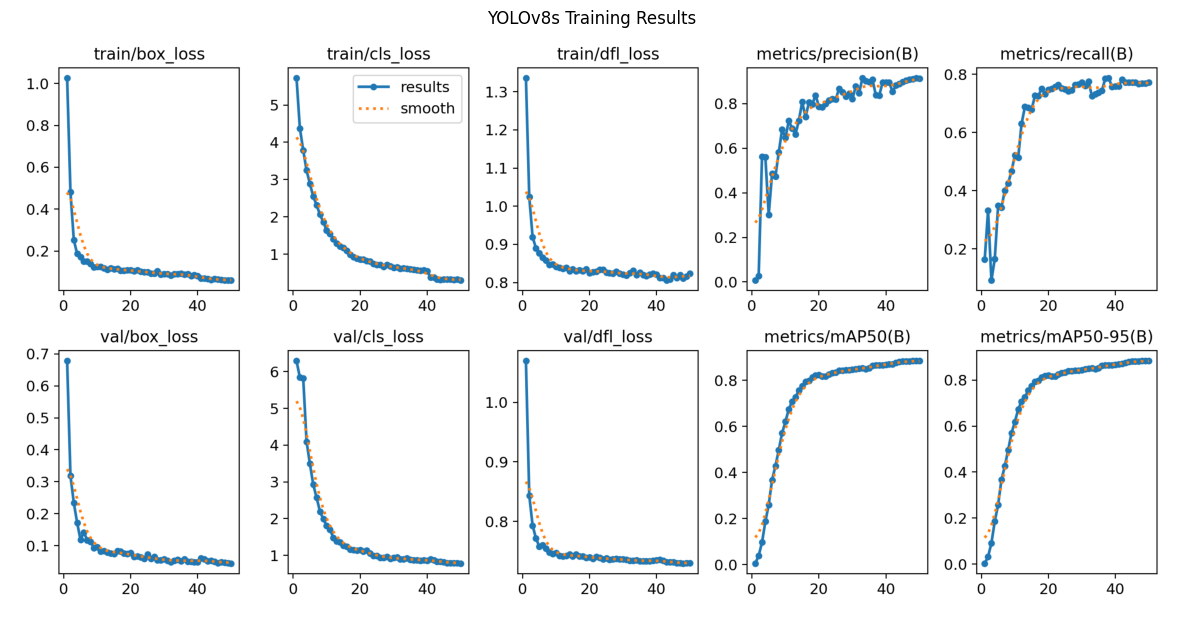

In [63]:
from PIL import Image
import matplotlib.pyplot as plt
import os

results_path = (
    "/content/drive/MyDrive/Deep Learning/"
    "YOLO_Runs/Milestone2_YOLOv8s_Mixed/"
    "results.png"
)

img = Image.open(results_path)

plt.figure(figsize=(15, 10))
plt.imshow(img)
plt.axis("off")
plt.title("YOLOv8s Training Results")
plt.show()

In [65]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Collect ground truth and predicted class IDs from test set
y_true = []
y_pred = []

test_results = best_model.predict(
    source=os.path.join(
        OUTPUT_ROOT,
        "images",
        "test"
    ),
    conf=0.25,
    imgsz=640,
    save=False,
    verbose=False
)

# Read true labels from YOLO txt files
for result in test_results:

    image_name = os.path.basename(result.path)

    label_file = os.path.join(
        OUTPUT_ROOT,
        "labels",
        "test",
        image_name.replace(".jpg", ".txt")
    )

    true_ids = []

    if os.path.exists(label_file):
        with open(label_file, "r") as f:
            for line in f:
                true_ids.append(
                    int(line.split()[0])
                )

    pred_ids = [
        int(box.cls[0])
        for box in result.boxes
    ]

    # Simple matching by class occurrence
    common = min(
        len(true_ids),
        len(pred_ids)
    )

    y_true.extend(
        true_ids[:common]
    )

    y_pred.extend(
        pred_ids[:common]
    )

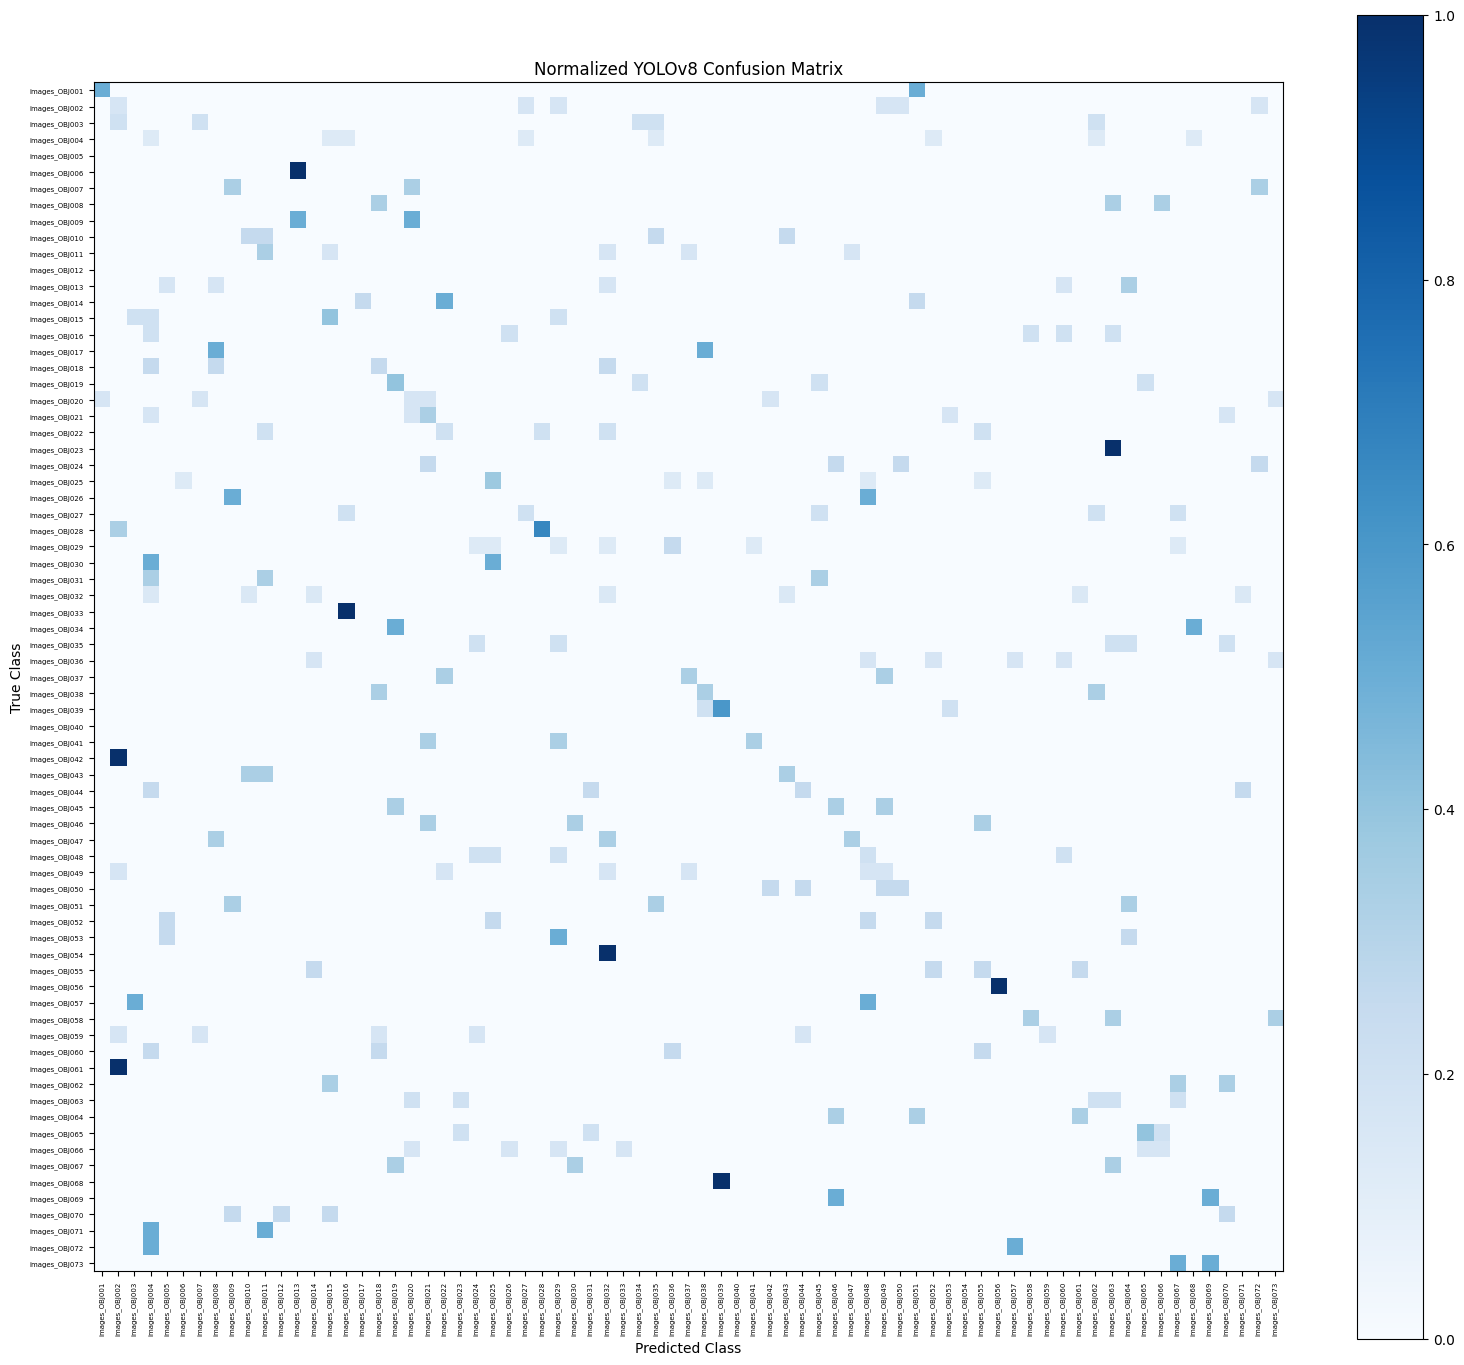

In [66]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    normalize="true"
)

plt.figure(figsize=(16, 14))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title(
    "Normalized YOLOv8 Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.colorbar()

plt.xticks(
    range(num_classes),
    class_names,
    rotation=90,
    fontsize=5
)

plt.yticks(
    range(num_classes),
    class_names,
    fontsize=5
)

plt.tight_layout()

plt.show()

In [67]:
import pandas as pd

final_metrics = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.50",
        "mAP@0.50:0.95"
    ],
    "Value": [
        test_metrics.box.mp,
        test_metrics.box.mr,
        test_metrics.box.map50,
        test_metrics.box.map
    ]
})

final_metrics

,Metric,Value
0,Precision,0.843409
1,Recall,0.753013
2,mAP@0.50,0.830640
3,mAP@0.50:0.95,0.830175


In [68]:
metrics_path = (
    "/content/drive/MyDrive/Deep Learning/"
    "Milestone2_YOLO_Dataset/"
    "final_metrics.csv"
)

final_metrics.to_csv(
    metrics_path,
    index=False
)

print("Saved:", metrics_path)

Saved: /content/drive/MyDrive/Deep Learning/Milestone2_YOLO_Dataset/final_metrics.csv


In [69]:
demo_folder = (
    "/content/drive/MyDrive/Deep Learning/"
    "Milestone2_YOLO_Dataset/demo_results"
)

os.makedirs(
    demo_folder,
    exist_ok=True
)

result_2x2.save(
    filename=os.path.join(
        demo_folder,
        "2x2_detection.jpg"
    )
)

print("2x2 detection saved.")

2x2 detection saved.


In [70]:
result_3x3.save(
    filename=os.path.join(
        demo_folder,
        "3x3_detection.jpg"
    )
)

print("3x3 detection saved.")

3x3 detection saved.


In [71]:
best_model_path = (
    "/content/drive/MyDrive/Deep Learning/"
    "YOLO_Runs/Milestone2_YOLOv8s_Mixed/"
    "weights/best.pt"
)

print("Best model path:")
print(best_model_path)

print(
    "Exists:",
    os.path.exists(best_model_path)
)

Best model path:
/content/drive/MyDrive/Deep Learning/YOLO_Runs/Milestone2_YOLOv8s_Mixed/weights/best.pt
Exists: True


In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import os

results_csv = (
    "/content/drive/MyDrive/Deep Learning/"
    "YOLO_Runs/Milestone2_YOLOv8s_Mixed/"
    "results.csv"
)

df = pd.read_csv(results_csv)

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print(df.columns)

Index(['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
       'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
       'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
       'lr/pg0', 'lr/pg1', 'lr/pg2'],
      dtype='object')


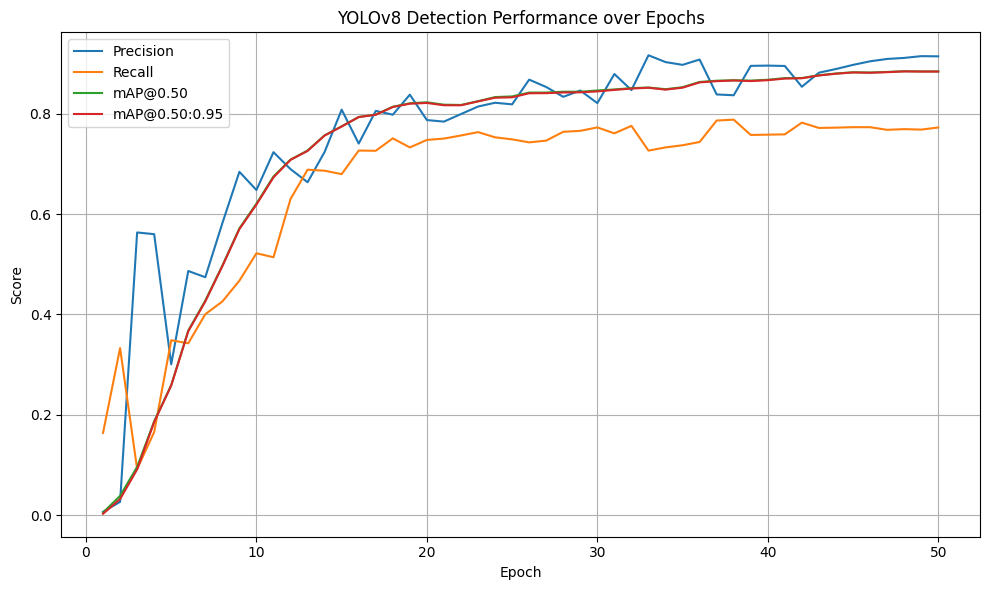

In [73]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["metrics/precision(B)"],
    label="Precision"
)

plt.plot(
    df["epoch"],
    df["metrics/recall(B)"],
    label="Recall"
)

plt.plot(
    df["epoch"],
    df["metrics/mAP50(B)"],
    label="mAP@0.50"
)

plt.plot(
    df["epoch"],
    df["metrics/mAP50-95(B)"],
    label="mAP@0.50:0.95"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("YOLOv8 Detection Performance over Epochs")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

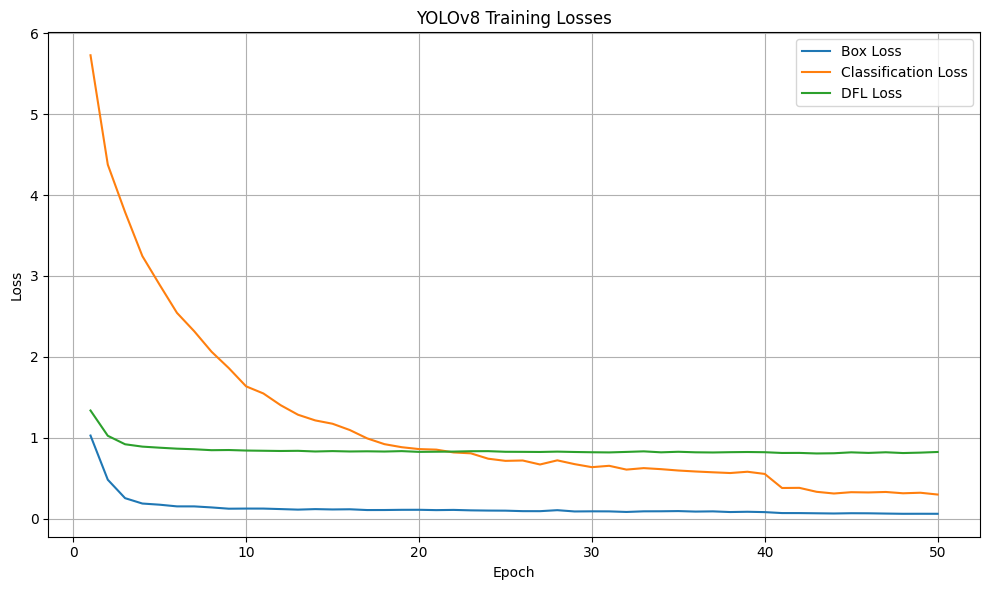

In [74]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/box_loss"],
    label="Box Loss"
)

plt.plot(
    df["epoch"],
    df["train/cls_loss"],
    label="Classification Loss"
)

plt.plot(
    df["epoch"],
    df["train/dfl_loss"],
    label="DFL Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv8 Training Losses")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

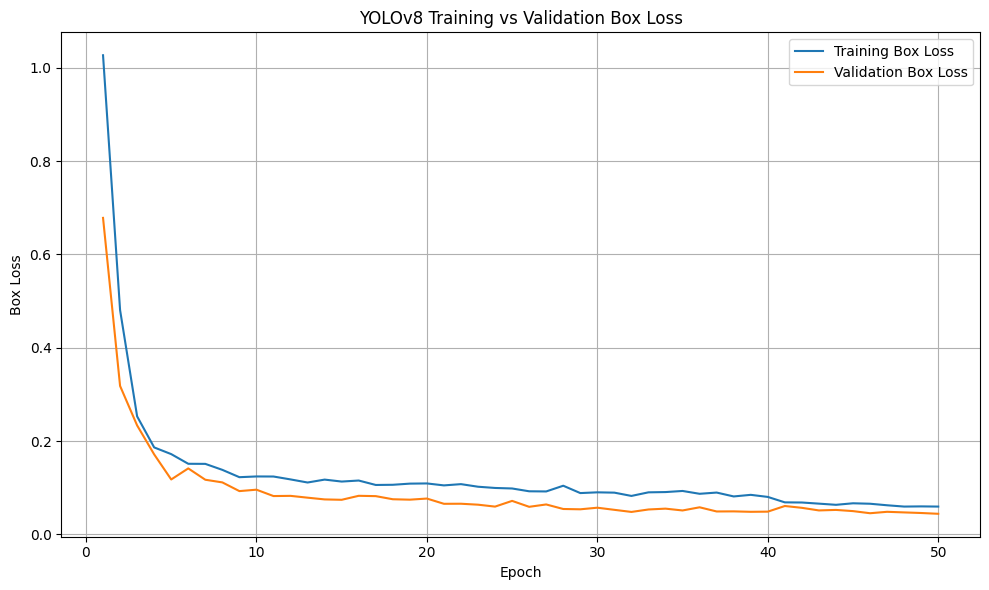

In [75]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/box_loss"],
    label="Training Box Loss"
)

plt.plot(
    df["epoch"],
    df["val/box_loss"],
    label="Validation Box Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("YOLOv8 Training vs Validation Box Loss")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

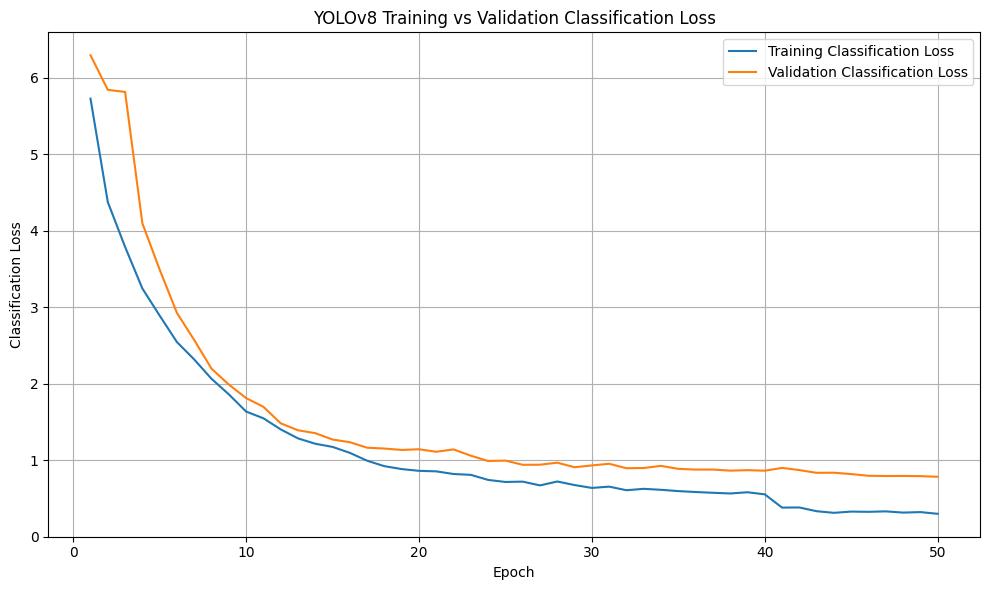

In [76]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/cls_loss"],
    label="Training Classification Loss"
)

plt.plot(
    df["epoch"],
    df["val/cls_loss"],
    label="Validation Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("YOLOv8 Training vs Validation Classification Loss")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [79]:
run_folder = (
    "/content/drive/MyDrive/Deep Learning/"
    "YOLO_Runs/Milestone2_YOLOv8s_Mixed"
)

print("Files in run folder:\n")

for file in sorted(os.listdir(run_folder)):
    print(file)

Files in run folder:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch360.jpg
train_batch361.jpg
train_batch362.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
weights


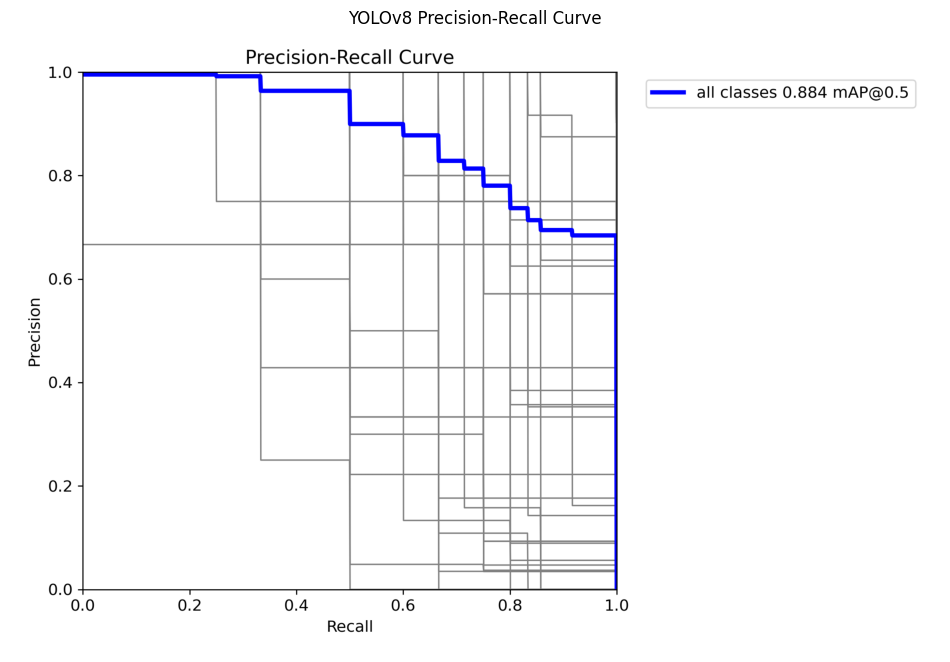

In [80]:
pr_curve_path = os.path.join(
    run_folder,
    "BoxPR_curve.png"
)

if os.path.exists(pr_curve_path):

    img = Image.open(pr_curve_path)

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("YOLOv8 Precision-Recall Curve")
    plt.show()

else:
    print("BoxPR_curve.png not found.")

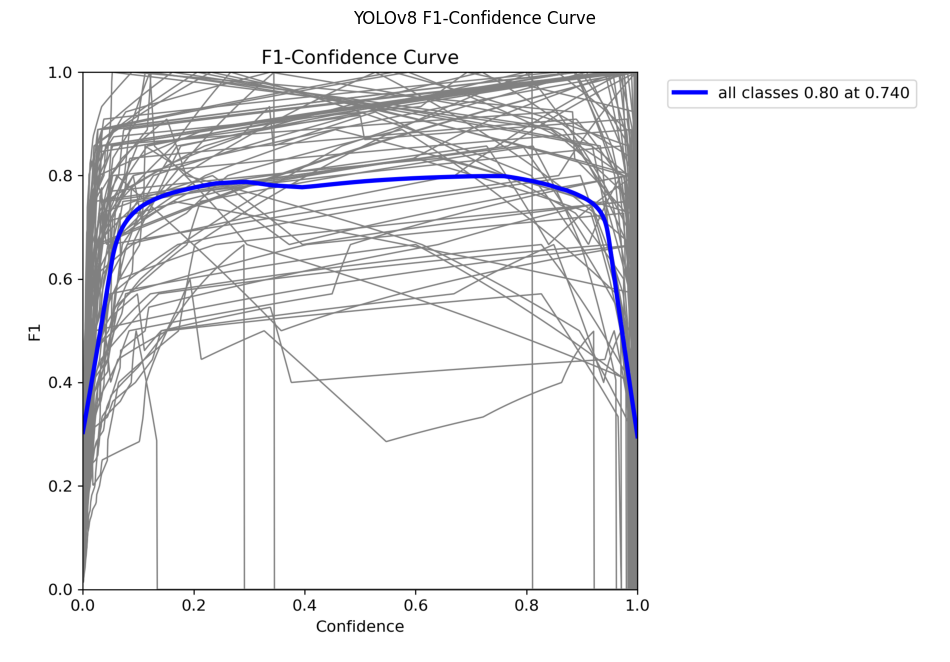

In [81]:
f1_curve_path = os.path.join(
    run_folder,
    "BoxF1_curve.png"
)

if os.path.exists(f1_curve_path):

    img = Image.open(f1_curve_path)

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("YOLOv8 F1-Confidence Curve")
    plt.show()

else:
    print("BoxF1_curve.png not found.")

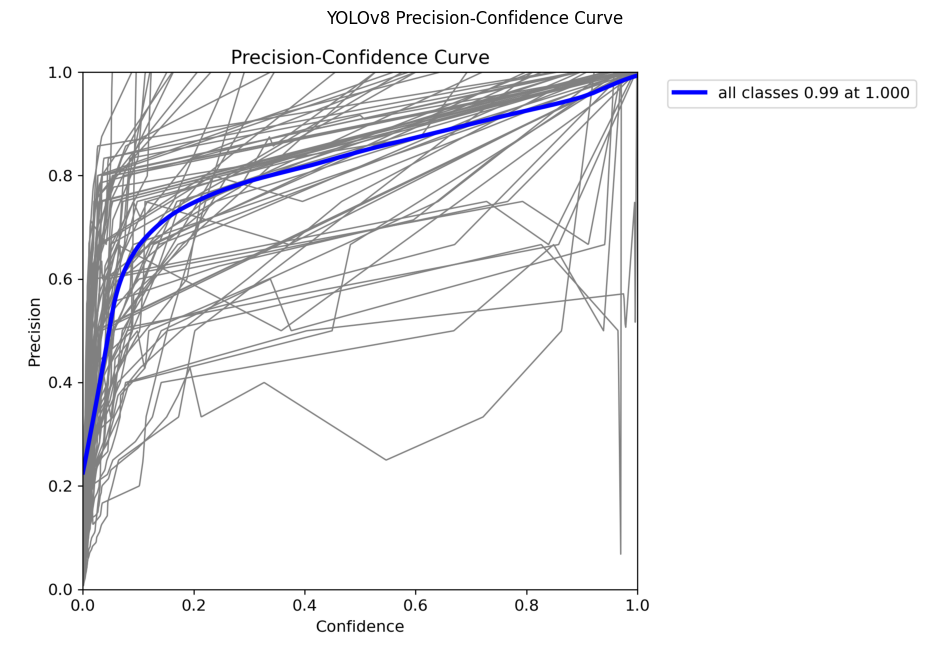

In [82]:
p_curve_path = os.path.join(
    run_folder,
    "BoxP_curve.png"
)

if os.path.exists(p_curve_path):

    img = Image.open(p_curve_path)

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("YOLOv8 Precision-Confidence Curve")
    plt.show()

else:
    print("BoxP_curve.png not found.")

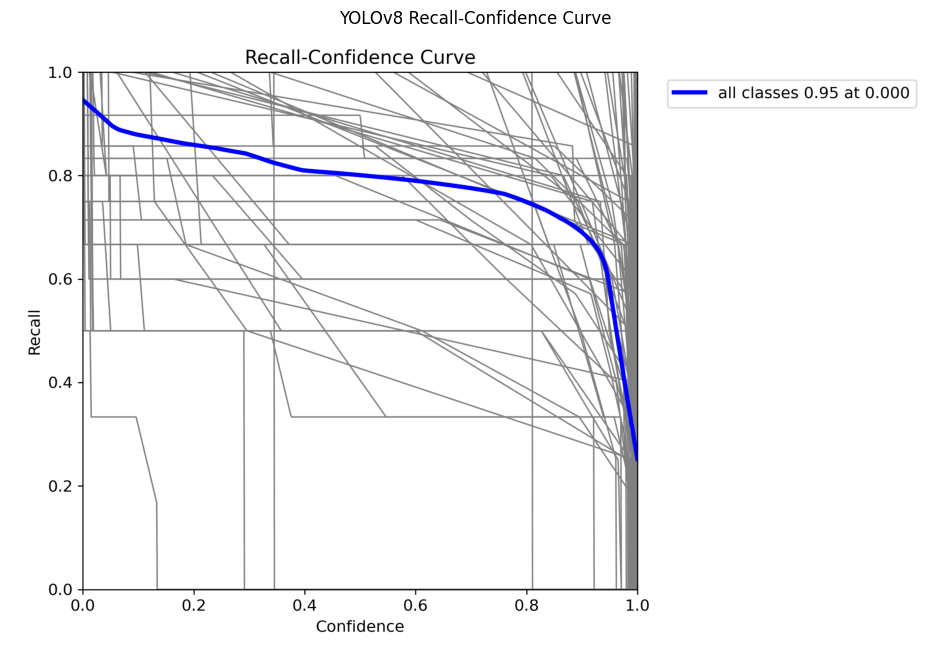

In [83]:
r_curve_path = os.path.join(
    run_folder,
    "BoxR_curve.png"
)

if os.path.exists(r_curve_path):

    img = Image.open(r_curve_path)

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("YOLOv8 Recall-Confidence Curve")
    plt.show()

else:
    print("BoxR_curve.png not found.")


In [84]:
final_metrics_percent = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.50",
        "mAP@0.50:0.95"
    ],
    "Percentage": [
        test_metrics.box.mp * 100,
        test_metrics.box.mr * 100,
        test_metrics.box.map50 * 100,
        test_metrics.box.map * 100
    ]
})

final_metrics_percent["Percentage"] = (
    final_metrics_percent["Percentage"].round(2)
)

final_metrics_percent

,Metric,Percentage
0,Precision,84.34
1,Recall,75.30
2,mAP@0.50,83.06
3,mAP@0.50:0.95,83.02
